<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/2.%20Features%20and%20Monthly%20Data%20(WBS%3A%202.4%20%26%202.5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2 Features and Monthly Data

Seven technical indicators for every ETF and trading day, the monthly table built from them, the variables list and an exploration of the 2010–2019 history.

**Input:** Daily Prices.parquet

**Outputs** (`data` folder):

| File | Folder | Contents |
|---|---|---|
| Monthly Data.parquet / .csv | processed | One row per universe, ETF and month-end: 7 features and the next-month return |
| Monthly Data Info.json | processed | Raw file checksum and table settings |
| Variables.csv | processed | Definition of every saved column |
| Monthly Data Checks.csv | reports | Results of all checks on the monthly table |
| Exploration Feature Summary.csv | reports | Feature distributions, ETF_A 2010–2019 |
| Exploration Feature Correlation.csv | reports | Monthly rank correlation of each feature with the next-month return |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: dba1188, Data download (2026-10-30 15:15)



In [2]:
import importlib
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import cleaning, config, features, variables

# Reload after a fresh clone
for module in (config, cleaning, features, variables):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 160)

## 2. Load the daily prices

The table is checked against its entries in the variables list.

In [3]:
clean = cleaning.load_clean(DIRS["processed"])
# Checksum of the frozen download, stored with the monthly table
raw_info = json.loads((DIRS["raw"] / config.FILES["raw_info"]).read_text())

print(f"{len(clean):,} rows, {clean['ticker'].nunique()} ETFs, "
      f"{clean['date'].min():%Y-%m-%d} to {clean['date'].max():%Y-%m-%d}")
print("Raw file checksum:", raw_info["md5"])
# Columns, types and ranges against the variables list
daily_checks = variables.check_table(clean, "Daily Prices")
print(daily_checks["status"].value_counts().to_dict())

71,408 rows, 16 ETFs, 2009-01-02 to 2026-09-30
Raw file checksum: 80113beee459649ee81eda775e0eee79
{'PASS': 14}


## 3. Features and monthly table

Indicators are computed from adjusted prices on every trading day and sampled at month-ends.

| Feature | Definition | Window (days) |
|---|---|---|
| Momentum | ln(P / P 21 days earlier) | 21 |
| Trend | SMA10 / SMA50 − 1 | 50 |
| Price bias | P / SMA10 − 1 | 10 |
| RSI | Wilder relative strength index, 0 to 100 | 14 |
| MACD | (MACD line − signal line) / P, EMA 12, 26, 9 | 35 |
| Bollinger width | 4 × std20 / SMA20 | 20 |
| Volume bias | V / SMA10(V) − 1, set to 0 on zero-volume days | 10 |

Each row dated t holds the features known at t and the return from t to the next month-end. SPY and XLK appear in both universes with identical values. The newest month-end has no return yet.

In [4]:
# Features on every trading day, then month-end rows with the next-month return
daily = features.daily_features(clean)
panel = features.build_panel(clean, daily)

# Rows per universe and period
print(panel.groupby(["universe", "period"]).size().unstack(fill_value=0))
print("Month-ends:", panel["date"].nunique())
print("Rows with volume bias set to 0:", int(panel["volume_filled"].sum()))
panel.head()

period    history  latest  test
universe                       
ETF_A         952       8   648
ETF_B        1190      10   810
Month-ends: 201
Rows with volume bias set to 0: 0


,date,universe,ticker,month,period,momentum,trend,price_bias,rsi,macd,bollinger,volume_bias,volume_filled,next_return
0,2010-01-29,ETF_A,AGG,2010-02,history,0.015311,0.001884,0.002213,60.561300,0.000721,0.016577,0.113872,False,0.001984
1,2010-01-29,ETF_A,DBC,2010-02,history,-0.085688,-0.028383,-0.038274,27.709466,-0.010150,0.147694,0.337347,False,0.041428
2,2010-01-29,ETF_A,EEM,2010-02,history,-0.073026,-0.022665,-0.046718,30.152954,-0.012620,0.161590,0.588597,False,0.017764
3,2010-01-29,ETF_A,EFA,2010-02,history,-0.063132,-0.014396,-0.042772,32.054382,-0.009334,0.116450,0.223724,False,0.002667
4,2010-01-29,ETF_A,JPXN,2010-02,history,-0.002551,0.035146,-0.032070,41.888634,-0.006087,0.077809,-0.630217,False,0.007662


## 4. Checks on the monthly table

Row counts, unique keys, complete and finite features, value ranges, the unlabelled newest month, an independent recomputation of the returns, and a look-ahead test: features at random month-ends are recomputed from prices cut off at that date and compared with the table. Every column is also checked against the variables list. The notebook stops on any FAIL.

In [5]:
panel_checks = features.validate_panel(panel, clean)
column_checks = variables.check_table(panel, "Monthly Data")

print(panel_checks.to_string(index=False))
print()
print(column_checks.to_string(index=False))

# Table checks and column checks in one report
all_checks = pd.concat([panel_checks.assign(column=""), column_checks], ignore_index=True)
if (all_checks["status"] == "FAIL").any():
    raise RuntimeError("A check on the monthly table failed.")

                 check status                                                                                            detail
       row count ETF_A   PASS                                                               1608 rows = 201 month-ends x 8 ETFs
       row count ETF_B   PASS                                                              2010 rows = 201 month-ends x 10 ETFs
           unique rows   PASS                                                                                  0 duplicate keys
     features complete   PASS                                                                          0 missing feature values
             rsi range   PASS                                                                      all values between 0 and 100
       bollinger range   PASS                                                                                all values above 0
         finite values   PASS                                                                        no 

## 5. Save

In [6]:
out = DIRS["processed"]
panel.to_parquet(out / config.FILES["monthly"], index=False)
panel.to_csv(out / "Monthly Data.csv", index=False)
variables.to_frame().to_csv(out / config.FILES["variables"], index=False)
all_checks.to_csv(DIRS["reports"] / config.FILES["checks"], index=False)

# Checksum and settings of this table
info = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "raw_file_md5": raw_info["md5"],
    "rows": {u: int(n) for u, n in panel["universe"].value_counts().items()},
    "month_ends": int(panel["date"].nunique()),
    "features": config.FEATURES,
    "test_months": [config.TEST_FIRST_MONTH, config.TEST_LAST_MONTH],
}
(out / config.FILES["monthly_info"]).write_text(json.dumps(info, indent=2))

356

## 6. Exploration of 2010–2019 (ETF_A)

Only the history before the test period is used.

### 6a. Feature distributions

In [7]:
# ETF_A, holding months before the test period
hist = panel[(panel["period"] == "history") & (panel["universe"] == "ETF_A")].copy()
print(f"{hist['date'].nunique()} months, {len(hist)} rows")

summary = hist[config.FEATURES].describe(percentiles=[0.05, 0.5, 0.95]).T
summary.to_csv(DIRS["reports"] / "Exploration Feature Summary.csv")
summary.round(4)

119 months, 952 rows


,count,mean,std,min,5%,50%,95%,max
momentum,952.0,0.0049,0.0407,-0.1972,-0.0719,0.0075,0.0640,0.1507
trend,952.0,0.0055,0.0283,-0.1049,-0.0511,0.0076,0.0472,0.0846
price_bias,952.0,0.0012,0.0144,-0.0625,-0.0227,0.0016,0.0249,0.0605
rsi,952.0,53.9481,10.7150,20.2007,36.0727,54.2856,70.4969,83.8322
macd,952.0,0.0000,0.0028,-0.0142,-0.0043,0.0000,0.0044,0.0116
bollinger,952.0,0.0556,0.0341,0.0048,0.0098,0.0506,0.1172,0.2286
volume_bias,952.0,0.2602,0.7094,-0.9825,-0.4564,0.1374,1.2962,6.2283


### 6b. Rank correlation with the next-month return

For each month, the Spearman correlation across the eight ETFs between a feature and the next-month return; mean, spread and t-statistic over all months.

In [8]:
def monthly_rank_correlation(df, feature):
    """Spearman correlation between a feature and the next-month return, one value per month."""
    return df.groupby("date").apply(
        lambda g: g[feature].corr(g["next_return"], method="spearman"), include_groups=False)

# Mean, spread and t-statistic of the monthly correlations
ic = pd.DataFrame({f: monthly_rank_correlation(hist, f) for f in config.FEATURES})
ic_table = pd.DataFrame({
    "mean correlation": ic.mean(),
    "std": ic.std(),
    "t-stat": ic.mean() / (ic.std() / np.sqrt(len(ic))),
    "share of months > 0": (ic > 0).mean(),
}).round(3)
ic_table.to_csv(DIRS["reports"] / "Exploration Feature Correlation.csv")
ic_table

,mean correlation,std,t-stat,share of months > 0
momentum,0.031,0.436,0.765,0.546
trend,0.091,0.419,2.380,0.555
price_bias,-0.041,0.408,-1.086,0.429
rsi,0.009,0.437,0.225,0.471
macd,-0.080,0.434,-2.005,0.420
bollinger,0.093,0.434,2.350,0.613
volume_bias,-0.080,0.409,-2.134,0.412


### 6c. Correlation between features

Spearman correlation between the seven features.

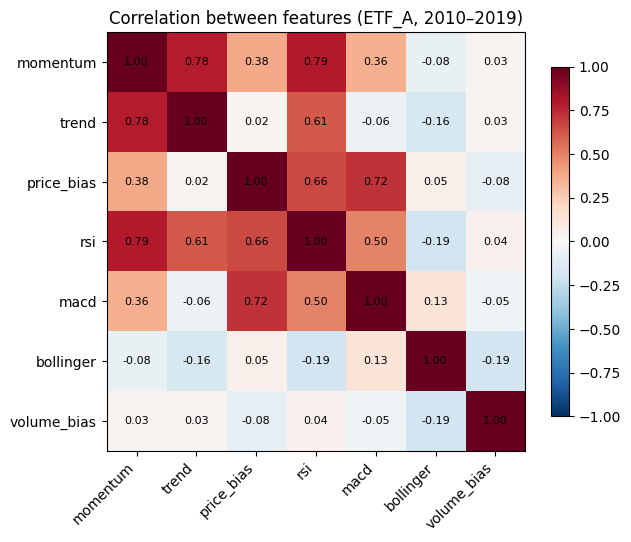

In [9]:
corr = hist[config.FEATURES].corr(method="spearman")

# Heatmap with values
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation between features (ETF_A, 2010–2019)")
plt.tight_layout()
plt.show()

## 7. Summary

In [10]:
# Key figures
passed = int((all_checks["status"] == "PASS").sum())
failed = int((all_checks["status"] == "FAIL").sum())
print(f"Month-ends:   {panel['date'].nunique()} ({panel['date'].min():%Y-%m} to {panel['date'].max():%Y-%m})")
for u, n in panel["universe"].value_counts().sort_index().items():
    print(f"Rows {u}:   {n:,}")
print(f"Checks:       {passed} passed, {failed} failed")

Month-ends:   201 (2010-01 to 2026-09)
Rows ETF_A:   1,608
Rows ETF_B:   2,010
Checks:       25 passed, 0 failed
